# Ventana deslizante y orden por tiempo esperado en CPIT

**Pregunta:** ¿La anticipación de una ventana deslizante mejora el plan Expected en la misma instancia y frente a la misma cota?

**Nivel**: 3

**Prerrequisitos**: 01-problem-and-published-data; 02-bound-and-feasible-plan

**Lectura**: 35 minutos

## Objetivos

Ejecutar la heurística de ventana deslizante respaldada por la literatura, compararla con Expected en una instancia compartida y explicar su adaptación por candidatos, cola optimista y presupuesto determinista. La respuesta separa evidencia medida de afirmaciones sobre otros casos.

## Preparación

Instale desde la raíz el entorno fijado con estas versiones. La celda informa las versiones realmente importadas.

```bash
pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Importar API y comprobar versiones.
import importlib.metadata as metadata
import json
from pathlib import Path
import sys
import matplotlib.pyplot as plt
sys.path.insert(0,str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case,DepositSpec,Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks','numpy','scipy','matplotlib'):
    print(package,metadata.version(package))

oreblocks 0.6.5
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Datos

PhaseFlow mantiene el generador determinista y el constructor de instancias; su código usa licencia MIT. El caso declara veta, semilla 31, tamaño 4×4×3, cuatro períodos y capacidades; no es dato de terreno. twin-porphyry-s es otro manifiesto derivado. Newman1 es un agregado del benchmark MineLib; los archivos por bloque tienen condiciones académicas de descarga y no se redistribuyen.

Procedencia por archivo: los agregados versionados son data/derived/manifests/newman1-published.json y data/derived/manifests/twin-porphyry-s.json. MineLib publica su registro en https://minelib.org/v1/Results.xhtml; MineLib mantiene el benchmark y sus archivos fuente tienen licencia de descarga académica. El generador sintético pertenece a PhaseFlow, https://github.com/fsantibanezleal/CAOS_PhaseFlow, bajo licencia MIT; su implementación está en data-pipeline/pipeline/model/instances.py. La semilla y el escenario del ejemplo se declaran en el código.

In [2]:
# Construir la instancia con el pipeline y leer agregados versionados.
case = Case(
    id='nb-vein-4x4x3',
    category='teaching',
    title_en='Small vein twin',
    title_es='Gemelo pequeño de veta',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(
        periods=4, discount_rate=0.08,
        capacity_fraction=(0.70, 0.50),
        resource_names=('mining', 'processing'),
    ),
)
instance=build_instance(case)
newman=json.loads(Path('../../../data/derived/manifests/newman1-published.json').read_text(encoding='utf-8'))
twin=json.loads(Path('../../../data/derived/manifests/twin-porphyry-s.json').read_text(encoding='utf-8'))
print('contrato aceptado:',instance.report.ok,'| bloques:',instance.n_blocks)
print('casos versionados:',newman.get('case_id',newman.get('case')),twin.get('case_id',twin.get('case')))

contrato aceptado: True | bloques: 48
casos versionados: newman1-published twin-porphyry-s


## Método

El modelo acumulado asigna valores descontados a slots de ventana y cola: se maximiza la suma de p_i(δ_j−δ_(j+1))y_ij, con monotonía y_i,j ≤ y_i,j+1, precedencia y_i,j ≤ y_a,j y capacidades por incremento. Cullenbine et al. (2011), https://doi.org/10.1007/s11590-011-0306-2, presentan la ventana deslizante para secuenciación de rajos. El dossier docs/methodologies/05_sliding-window.md documenta la adaptación OreBlocks y sus límites.

Cullenbine, Wood y Newman presentan la heurística de ventana temporal deslizante para secuenciar rajos como una estrategia con anticipación: resolver un horizonte corto en conjunto, fijar el primer período y avanzar. La motivación es el acoplamiento temporal. Un bloque atractivo porque habilita otro posterior puede aparecer en la optimización conjunta del horizonte, a diferencia de una clasificación puramente miope. El artículo es la fuente metodológica; este notebook ejecuta OreBlocks fijado, no el código original de los autores ni su benchmark.

El dossier del producto explica una adaptación material. Una ventana industrial completa puede ser demasiado grande sin solver comercial; por eso OreBlocks construye un prefijo candidato cerrado, guiado por PL y dimensionado según la capacidad de la ventana. El cierre por precedencia importa: no se deben omitir requisitos de los bloques seleccionados. El paquete completa el cierre de forma explícita. Esta política es un detalle de la implementación del producto, por lo que el experimento no es una reproducción exacta del artículo.

Dentro de la ventana, las variables acumuladas preservan la extracción monótona. La selección acumulada de un bloque no disminuye entre posiciones; cada bloque elegido requiere sus predecesores en la misma posición; las filas de recursos limitan incrementos por período. El horizonte no modelado se representa como cola agregada. Su capacidad resume la capacidad restante y su factor de descuento es optimista, de modo que puede sobrevalorar extracción futura. Es una característica conocida de la relajación, no una predicción del flujo de caja realizado.

TopoSort con valor esperado es la referencia porque usa los mismos datos de precedencia y capacidad y es la heurística temporal directamente comparable del paquete. Ejecutamos ambos métodos sobre un caso de veta construido por PhaseFlow con los mismos cuatro períodos, economía y límites de recursos. La instancia pequeña permite exponer la mecánica e inspeccionar las asignaciones devueltas. No mide rendimiento del producto a escala completa ni reproduce un caso minero publicado.

Paso 1. Vuelva a calcular el certificado de recurso en el caso compartido.

In [3]:
# Calcular la menor cota válida de recursos.
relaxations = [
    ob.cpit_lp_relaxation(
        instance.cpit, instance.precedence, resource=resource
    )
    for resource in range(instance.cpit.coef.shape[0])
]
bound = min(result.bound for result in relaxations)
print('cota común' if True else 'shared bound', round(bound, 2))

cota común 284685.82


Paso 2. Ejecute Expected para fijar el comparador, conservando datos y capacidades.

In [4]:
# Obtener el plan Expected desde OreBlocks.
expected, _ = ob.solve_cpit(
    instance.cpit, instance.precedence, method='expected', local_search=False
)
print('VPN' if True else 'VPN', round(expected.npv, 2))

VPN 179191.57


## Comparación

Cullenbine, Wood y Newman (2011), https://doi.org/10.1007/s11590-011-0306-2, proponen resolver conjuntamente una ventana, fijar su primer período y deslizarla. Esto anticipa efectos de decisiones tempranas sobre períodos cercanos, pero su publicación no es una promesa de superioridad en todo caso. La implementación del paquete usa candidatos guiados por relajación y cola optimista; el resultado aquí corresponde a esa implementación y sus parámetros, no al solver ni a los datos originales del artículo. El dossier de PhaseFlow registra victorias y derrotas en su matriz preparada.

La tabla experimental usa un certificado superior común para ambos candidatos. Cada fila incluye VPN, bloques extraídos, brecha y control de dirección de cota. La brecha mide distancia al certificado, no suboptimalidad demostrada respecto del óptimo entero desconocido. El VPN mayor es mejor para esta ejecución y estas restricciones. Otro depósito, cola, prefijo candidato o presupuesto del solver podría cambiar el orden.

Dos figuras revelan dimensiones distintas del resultado. La comparación de objetivo muestra valores factibles frente al mismo techo. El perfil de carga señala los períodos y recursos que determinan el plan. Ninguna figura codifica todos los arcos de precedencia; use el validador del paquete para revisar el plan retornado. Las líneas son límites, no caudales operativos medidos, y acercarse a una línea no constituye recomendación de producción.

La literatura fundamenta la familia de ventanas deslizantes y su papel en planificación de rajos; el dossier del producto registra la versión probada, la regla de candidatos, los compromisos de tiempo y los casos donde pierde. Usamos ese dossier para evitar afirmar que anticiparse siempre gana. En la matriz preparada, la ventana mejora muchos casos, pero pierde en algunos. Esta ejecución pequeña concuerda con el mecanismo, no replica independientemente las mediciones del producto.

Paso 3. Ejecute la ventana con nodo límite reproducible; esto limita búsqueda sin depender del reloj del equipo.

In [5]:
# Resolver ventanas conjuntas y fijar parámetros del experimento.
window = ob.sliding_window_schedule(
    instance.cpit, instance.precedence,
    window=2, fix=1, node_limit=50, mip_gap=0.01,
    relaxation=relaxations[0],
)
print('VPN' if True else 'VPN', round(window.npv, 2), '| bloques' if True else '| bloques', window.mined_blocks)

VPN 237344.67 | bloques 4


Valide ambos planes con los mismos controles.

In [6]:
# Comparar primero el plan base con controles independientes.
expected_controls = ob.run_controls(instance.cpit, instance.precedence, expected)
print('controles Expected:', expected_controls.__dict__)

controles Expected: {'duality_set_matches': True, 'duality_bound_error': 0.0, 'bound_geq_feasible': True, 'order_invariant': True, 'order_invariance_error': 0.0}


Ahora valide por separado el plan de ventana con los mismos controles; esta salida responde por este candidato y no hereda el resultado Expected.

In [7]:
# Comprobar dirección de cota e invariancia del plan de ventana.
window_controls = ob.run_controls(instance.cpit, instance.precedence, window)
print('controles de ventana:', window_controls.__dict__)

controles de ventana: {'duality_set_matches': True, 'duality_bound_error': 0.0, 'bound_geq_feasible': True, 'order_invariant': True, 'order_invariance_error': 0.0}


La figura izquierda sitúa VPN de cada plan bajo la cota superior compartida; no convierte una heurística en óptimo.

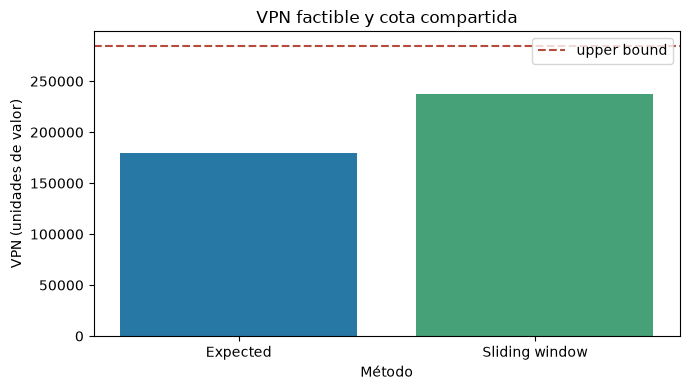

In [8]:
# Graficar valores factibles y cota superior compartida.
labels = ['Expected', 'Sliding window']
values = [expected.npv, window.npv]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(labels, values, color=['#2878a5', '#46a078'])
ax.axhline(bound, color='#b64b3b', linestyle='--', label='upper bound')
ax.set(title='VPN factible y cota compartida', xlabel='Método', ylabel='VPN (unidades de valor)')
ax.legend()
fig.tight_layout()
plt.show()

La reproducibilidad requiere declarar solver y presupuesto de parada. Usamos el límite determinista de nodos de OreBlocks, no un límite de tiempo real, porque las paradas por reloj pueden producir planes dependientes del equipo. La longitud de ventana y el prefijo fijado quedan explícitos. Si repite el experimento, mantenga esos valores; modificarlos responde otra pregunta. El tiempo de esta instancia compacta no estima casos productivos.

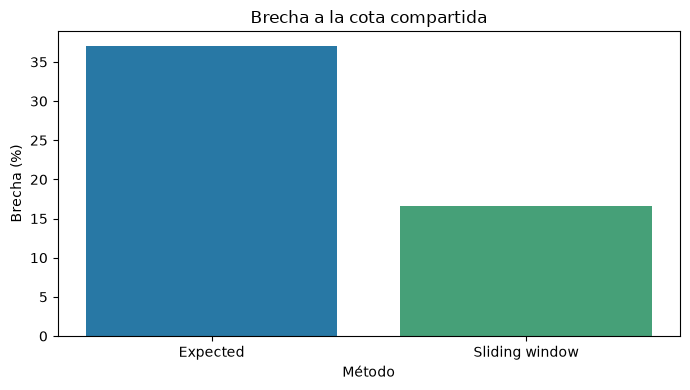

In [9]:
# Graficar brecha frente a la misma cota.
gaps = [100 * (bound - value) / bound for value in values]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(labels, gaps, color=['#2878a5', '#46a078'])
ax.set(title='Brecha a la cota compartida', xlabel='Método', ylabel='Brecha (%)')
fig.tight_layout()
plt.show()

Interprete el resultado por capas: la aceptación del contrato confirma construcción consistente; el paquete devuelve un candidato factible; los controles independientes revisan dirección de cota e invariancia al orden; la relajación aporta el certificado superior; y la comparación aísla una decisión heurística. Ninguna capa valida el escenario frente a un plan minero real. Para esa afirmación use el dossier y traza versionada del caso publicado, con procedencia separada del caso sintético.

## Resultados

**Respuesta:** Expected obtuvo VPN 179191.57 y brecha 37.056%; sliding window obtuvo 237344.67 y brecha 16.629% con la misma cota 284685.82. La diferencia se midió con límite de nodos en una instancia sintética pequeña. No demuestra optimalidad ni generaliza a otros depósitos.

In [10]:
# Responder con la comparación calculada.
print('Expected', round(expected.npv, 2), 'brecha %', round(100*(bound-expected.npv)/bound, 3))
print('Ventana deslizante', round(window.npv, 2), 'brecha %', round(100*(bound-window.npv)/bound, 3))

Expected 179191.57 brecha % 37.056
Ventana deslizante 237344.67 brecha % 16.629


## Resumen

Interprete el resultado por capas: la aceptación del contrato confirma construcción consistente; el paquete devuelve un candidato factible; los controles independientes revisan dirección de cota e invariancia al orden; la relajación aporta el certificado superior; y la comparación aísla una decisión heurística. Ninguna capa valida el escenario frente a un plan minero real. Para esa afirmación use el dossier y traza versionada del caso publicado, con procedencia separada del caso sintético.

## Referencias

- Cullenbine, Wood and Newman (2011), sliding-window heuristic: https://doi.org/10.1007/s11590-011-0306-2
- Chicoisne et al. (2012), CPIT relaxation: https://doi.org/10.1287/opre.1120.1050
- Rivera Letelier et al. (2020), scheduling methods: https://doi.org/10.1287/opre.2019.1965
- MineLib Newman1: https://minelib.org/v1/Results.xhtml
- Product dossier: docs/methodologies/05_sliding-window.md
- Repositorio PhaseFlow y generador de gemelos sintéticos: https://github.com/fsantibanezleal/CAOS_PhaseFlow